## Лабораторная работа №1 | Вариант 4

Выполнил: Агапкин Артем Дмитриевич

### 1. Numpy

In [1]:
import numpy as np

1. Найти индексы не нулевых элементов массива [1,2,0,0,4,0]

In [2]:
arr = [1, 2, 0, 0, 4, 0]
print(np.nonzero(arr)[0])

[0 1 4]


2. Создайте единичную матрицу размером 3х3

In [3]:
print(np.eye(3))

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


3. Создайте матрицу-шахматную доску 8х8 используя функцию `tile`

In [4]:
print(np.tile(np.array([[0, 1], [1, 0]]), (4, 4)))

[[0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]]


4. Дан 1D массив, удалите все элементы которые входят в диапазон `[3, 8]` inplace

In [5]:
arr = [0, 4, 4, 2, 1, 4, 8, 7, 10, 15]
a = np.array(arr)
mask = (a < 3) | (a > 8)
k = mask.sum()
a[:k] = a[mask]
a.resize(k, refcheck=False)
print(a)


[ 0  2  1 10 15]


5. Создайте случайный вектор размером 10 элементов и замените максимальный элемент на 0

In [6]:
a = np.random.default_rng(42).random(10)
a[a == a.max()] = 0
print(a)

[0.77395605 0.43887844 0.85859792 0.69736803 0.09417735 0.
 0.7611397  0.78606431 0.12811363 0.45038594]


6. Как распечатать все значения в массиве?

In [7]:
b = np.arange(1000)
with np.printoptions(threshold=np.inf):
    print(b)

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236 237 238 239 240 241 242 243 244 245 24

7. Рассмотрим случайный вектор с формой 100х2, представляющей координаты, и найдем расстояния от точки к точке

In [8]:
X = np.random.default_rng(42).random((100, 2))
D = np.sqrt(np.sum((X.reshape(100, 1, 2) - X.reshape(1, 100, 2)) ** 2, axis=2))

print(D)

[[0.         0.2719947  0.86613689 ... 0.67277843 0.46935703 0.59165638]
 [0.2719947  0.         0.81348895 ... 0.87515404 0.31399077 0.76698338]
 [0.86613689 0.81348895 0.         ... 0.79854455 0.51521425 0.67311135]
 ...
 [0.67277843 0.87515404 0.79854455 ... 0.         0.82609759 0.13797631]
 [0.46935703 0.31399077 0.51521425 ... 0.82609759 0.         0.69334849]
 [0.59165638 0.76698338 0.67311135 ... 0.13797631 0.69334849 0.        ]]


8. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [9]:
a = (np.random.default_rng(42).random(10) * 100).astype(np.float32)
b = a.view(np.int32)
b[:] = a
print(b)


[77 43 85 69  9 97 76 78 12 45]


9. Как прочитать заданный файл?
```
1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11
```

In [10]:
a = np.genfromtxt('data.txt', delimiter=',')
print(a)

[[ 1.  2.  3.  4.  5.]
 [ 6. nan nan  7.  8.]
 [nan nan  9. 10. 11.]]


10. Какой эквивалент enumerate для numpy массивов?

In [11]:
a = np.array([[1, 2], [3, 4], [5, 6]])
for i, value in np.ndenumerate(a):
  print(i, value)

(0, 0) 1
(0, 1) 2
(1, 0) 3
(1, 1) 4
(2, 0) 5
(2, 1) 6


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом

Файл: `russian-housing-market.csv`

```
price_doc - Цена продажи
id - Id транзакции
timestamp - Дата транзакции
full_sq - суммарная площадь в квадратных метрах, включая лоджию, валконы и отдельные нежилые помещения
life_sq - жилая площаль в квадратных метрах, исключая лоджии, балконы и прочие нежилые помещения
floor - для апартаментов, этаж помещения
max_floor - количество этажей в здании
material - материал стен
build_year - год постройки
num_room - количество жилых комнат
kitch_sq - площадь кухни
state - состояние апартаментов
product_type - покупка или инвестиция собственника-арендатора
sub_area - название района
```

In [12]:
import pandas as pd
pd.set_option("display.precision", 2)

In [13]:
# Load dataset here
df = pd.read_csv("russian-housing-market.csv")
df.head()

,id,timestamp,full_sq,life_sq,floor,max_floor,material,build_year,num_room,kitch_sq,state,product_type,sub_area,price_doc
0,1,2011-08-20,43,27.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Bibirevo,5850000
1,2,2011-08-23,34,19.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Nagatinskij Zaton,6000000
2,3,2011-08-27,43,29.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Tekstil'shhiki,5700000
3,4,2011-09-01,89,50.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Mitino,13100000
4,5,2011-09-05,77,77.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Basmannoe,16331452


1. Посчитайте количество записей в датасете с отсутствующей информацией о жилой площади жилого помещения

In [14]:
print(df["life_sq"].isna().sum())

6383


2. Предложите способ заменить отсутствующие значения из пункта 1 и реализуйте его. Способ нужно аргументировать(сказать почему это достаточно хорошее приближение)

In [15]:
df["life_sq"] = df["life_sq"].fillna(df["life_sq"].median())
# берем медианное значение, так как в датасете есть выбросы, а она устойчива к ним

3. Какие значения имеет 25, 50 и 75 перцентили полной площади помещения

In [16]:
df["full_sq"].describe()[["25%", "50%", "75%"]]

25%    38.0
50%    49.0
75%    63.0
Name: full_sq, dtype: float64

4. Посчитайте среднюю стоимость продажи помещений с общей площадью от 50 до 70 квадратных метров

In [17]:
print(df[(df["full_sq"] >= 50) & (df["full_sq"] <= 70)]["price_doc"].mean())

7243041.190994609


5. Какая максимальная этажность здания представлена в датасете

In [18]:
print(df["max_floor"].max())

117.0


6. Выявите район с самым дорогим жильем

In [19]:
df.groupby(["sub_area"])["price_doc"].agg(["mean", "count"]).sort_values(by="mean", ascending=False).head(1)

,mean,count
sub_area,,
Hamovniki,2.01e+07,90


7. Посчитайте среднюю стоимость за квадратный метр жилья в Митино(Mitino)

In [20]:
df["price_sq"] = df["price_doc"] / df["full_sq"]
print(df[df["sub_area"] == "Mitino"]["price_sq"].mean())

171841.39999559196


8. Посчитайте среднюю площадь комнаты в Бибирево

In [21]:
bibirevo = df[(df["sub_area"] == "Bibirevo") & (df["num_room"] > 0)]
print(bibirevo["life_sq"].sum() / bibirevo["num_room"].sum())

15.100609756097562


9. Проанализируйте есть ли разница в цене между квартирами на 1 и 9 этажах

In [22]:
a = ["price_doc", "full_sq", "price_sq"]

df[df["floor"].isin([1, 9])].groupby(["floor"])[a].median()
# как видно из медианной цены, на 1 этаже цена ниже

,price_doc,full_sq,price_sq
floor,,,
1.0,5.57e+06,44.0,134494.95
9.0,6.40e+06,48.0,138513.51


10. Найдите минимальную стоимость квартиры с жилой площадью не менее 60 квадратных метров, не менее чем 3мя комнатами и не ниже чем на 5 этаже

In [23]:
print(df[(df["life_sq"] >= 60) & (df["num_room"] >= 3) & (df["floor"] >= 5)]["price_doc"].min())

1000000


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Как менялась средняя цена квартиры в Нагатинском Затоне(Nagatinski Zaton) с течением времени

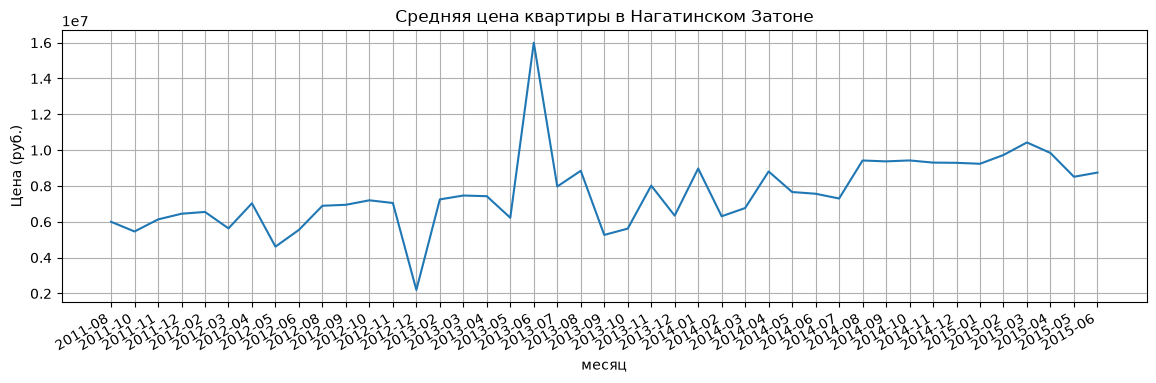

In [24]:
import matplotlib.pyplot as plt

df["timestamp"] = pd.to_datetime(df["timestamp"])
zaton = df[df["sub_area"] == "Nagatinskij Zaton"]
month = zaton.groupby(zaton["timestamp"].dt.strftime("%Y-%m"))["price_doc"].mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(month.index, month.values)
ax.set(title='Средняя цена квартиры в Нагатинском Затоне', xlabel='месяц', ylabel='Цена (руб.)')
ax.grid()
fig.autofmt_xdate()
plt.show()

2. Постройте гистограмму распределения цен на квартиры с общей площадью более 50 кв.метров

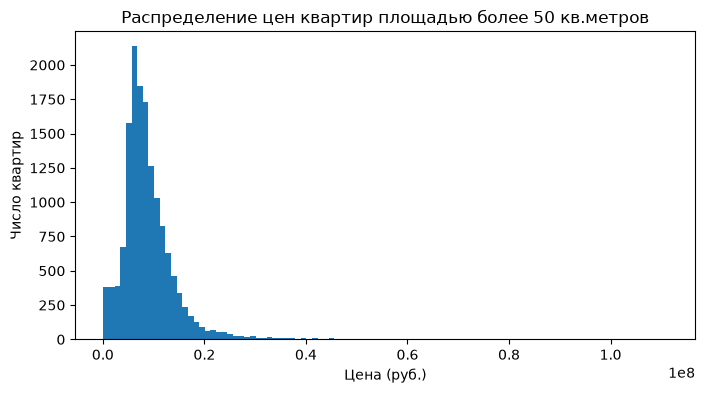

In [25]:
big = df[df["full_sq"] > 50]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(big["price_doc"], bins=100)
ax.set(title='Распределение цен квартир площадью более 50 кв.метров', xlabel='Цена (руб.)', ylabel='Число квартир')
plt.show()

3. Визуализируйте количество проданных квартир в разных районах

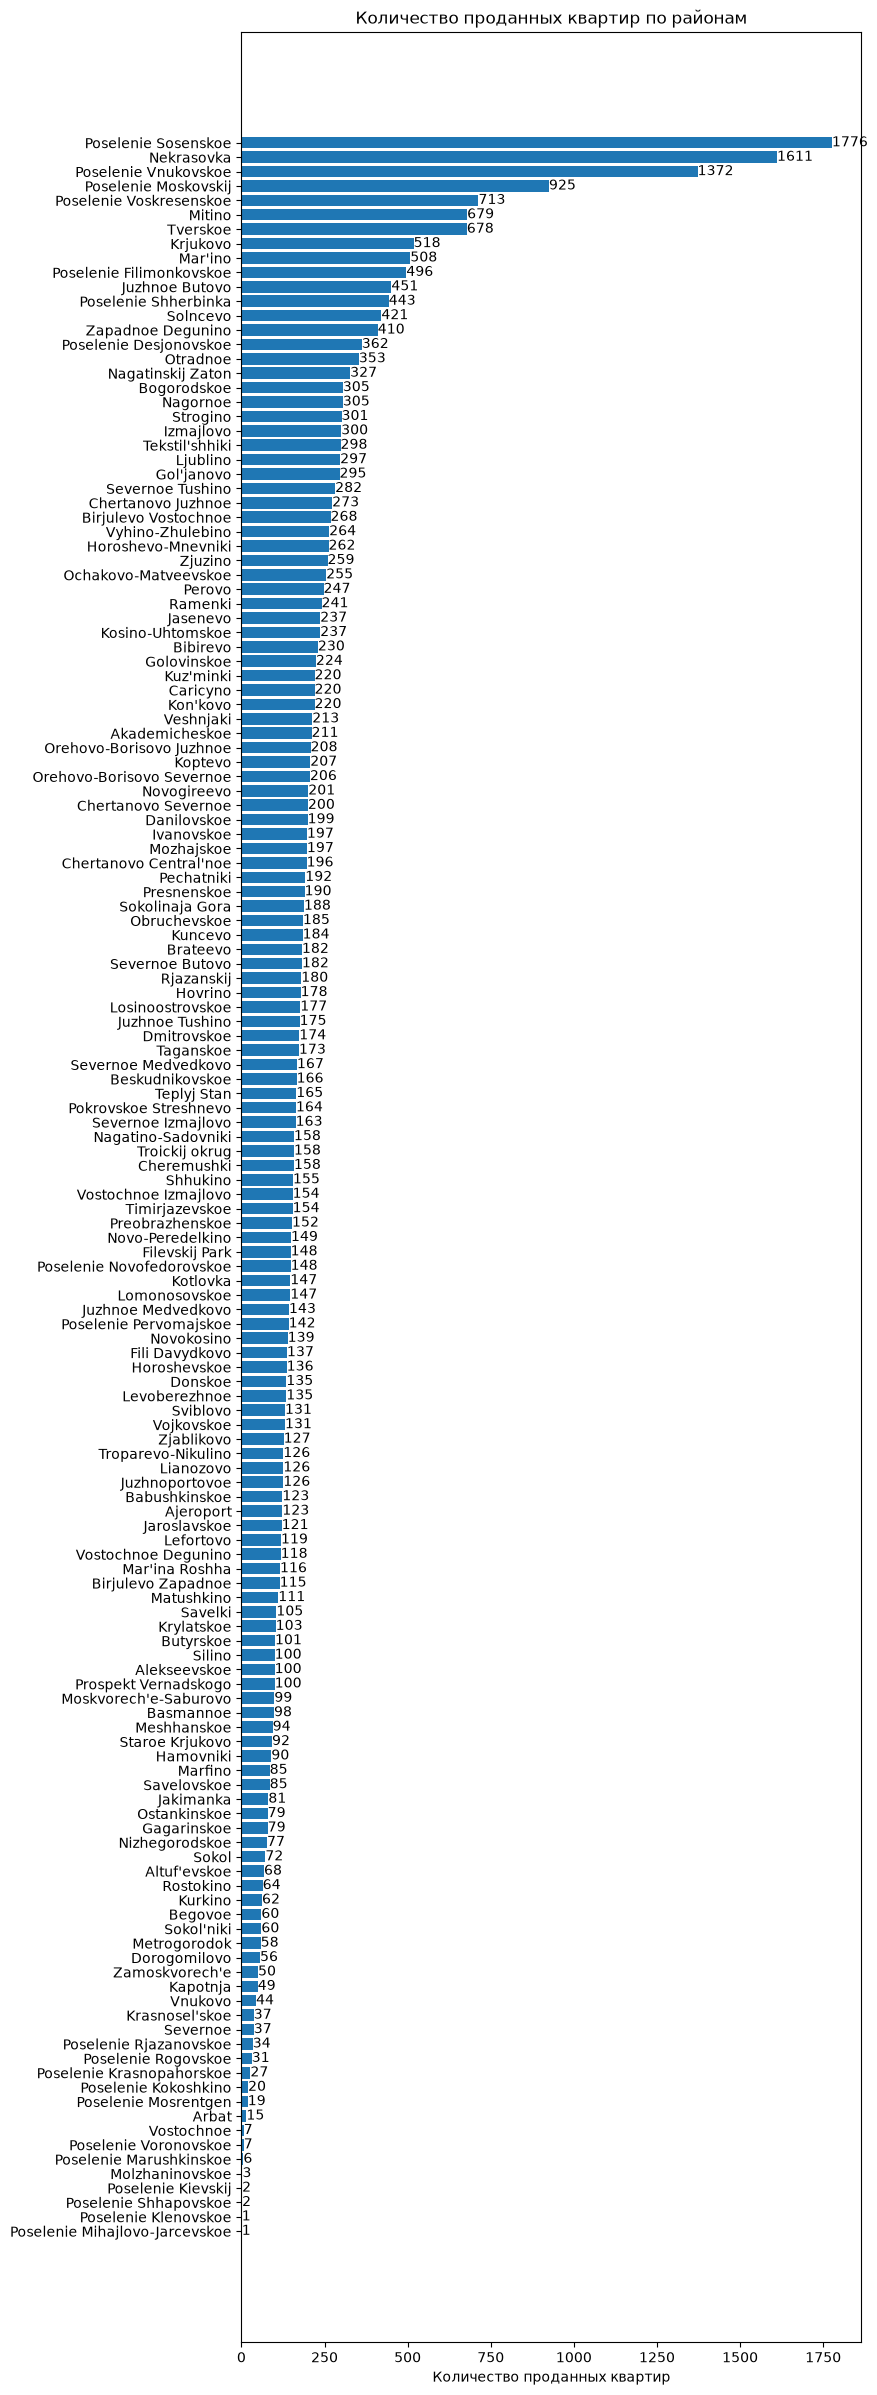

In [26]:
counts = df["sub_area"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 30))
bars = ax.barh(counts.index, counts.values)
ax.bar_label(bars)
ax.set(xlabel='Количество проданных квартир', title='Количество проданных квартир по районам')
plt.show()

4. Постройте box plot отображающий распределение полных площадей квартир в Басманном районе

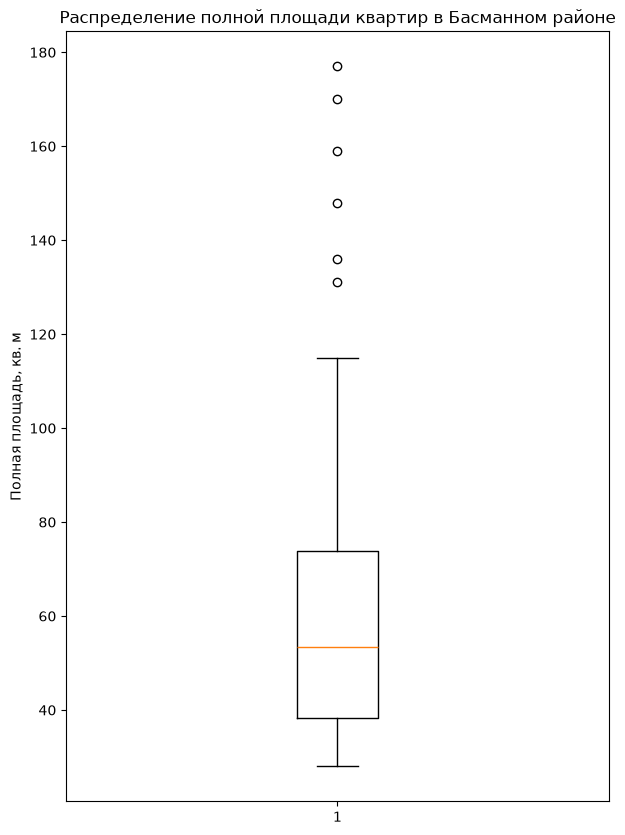

In [27]:
basmannoe = df[df["sub_area"] == "Basmannoe"]["full_sq"]

plt.figure(figsize=(7, 10))
plt.boxplot(basmannoe)
plt.title('Распределение полной площади квартир в Басманном районе')
plt.ylabel('Полная площадь, кв. м')
plt.show()

5. Визуализируйте зависимость средней стоимости квартир в зависимости от этажа

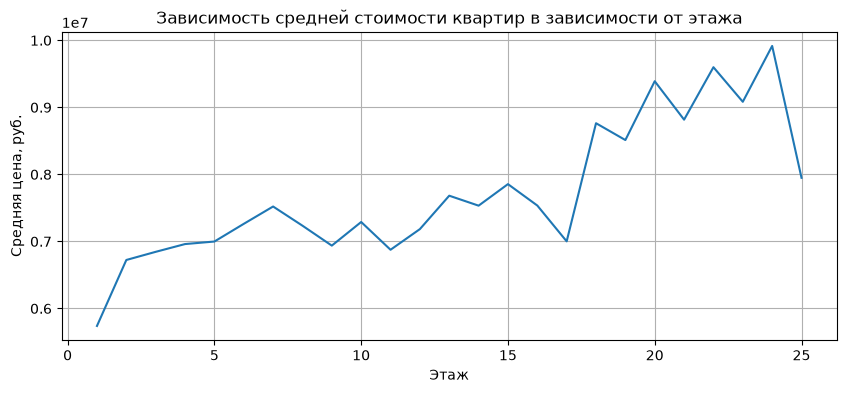

In [28]:
floor_stats = df.groupby("floor")["price_doc"].agg(["mean", "count"])
floor_stats = floor_stats[floor_stats["count"] >= 30]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(floor_stats.index, floor_stats["mean"])
ax.set(title='Зависимость средней стоимости квартир в зависимости от этажа', xlabel='Этаж', ylabel='Средняя цена, руб.')
ax.grid()
plt.show()

6. Покажите как меняется средняя площадь квартир в зависимости от района

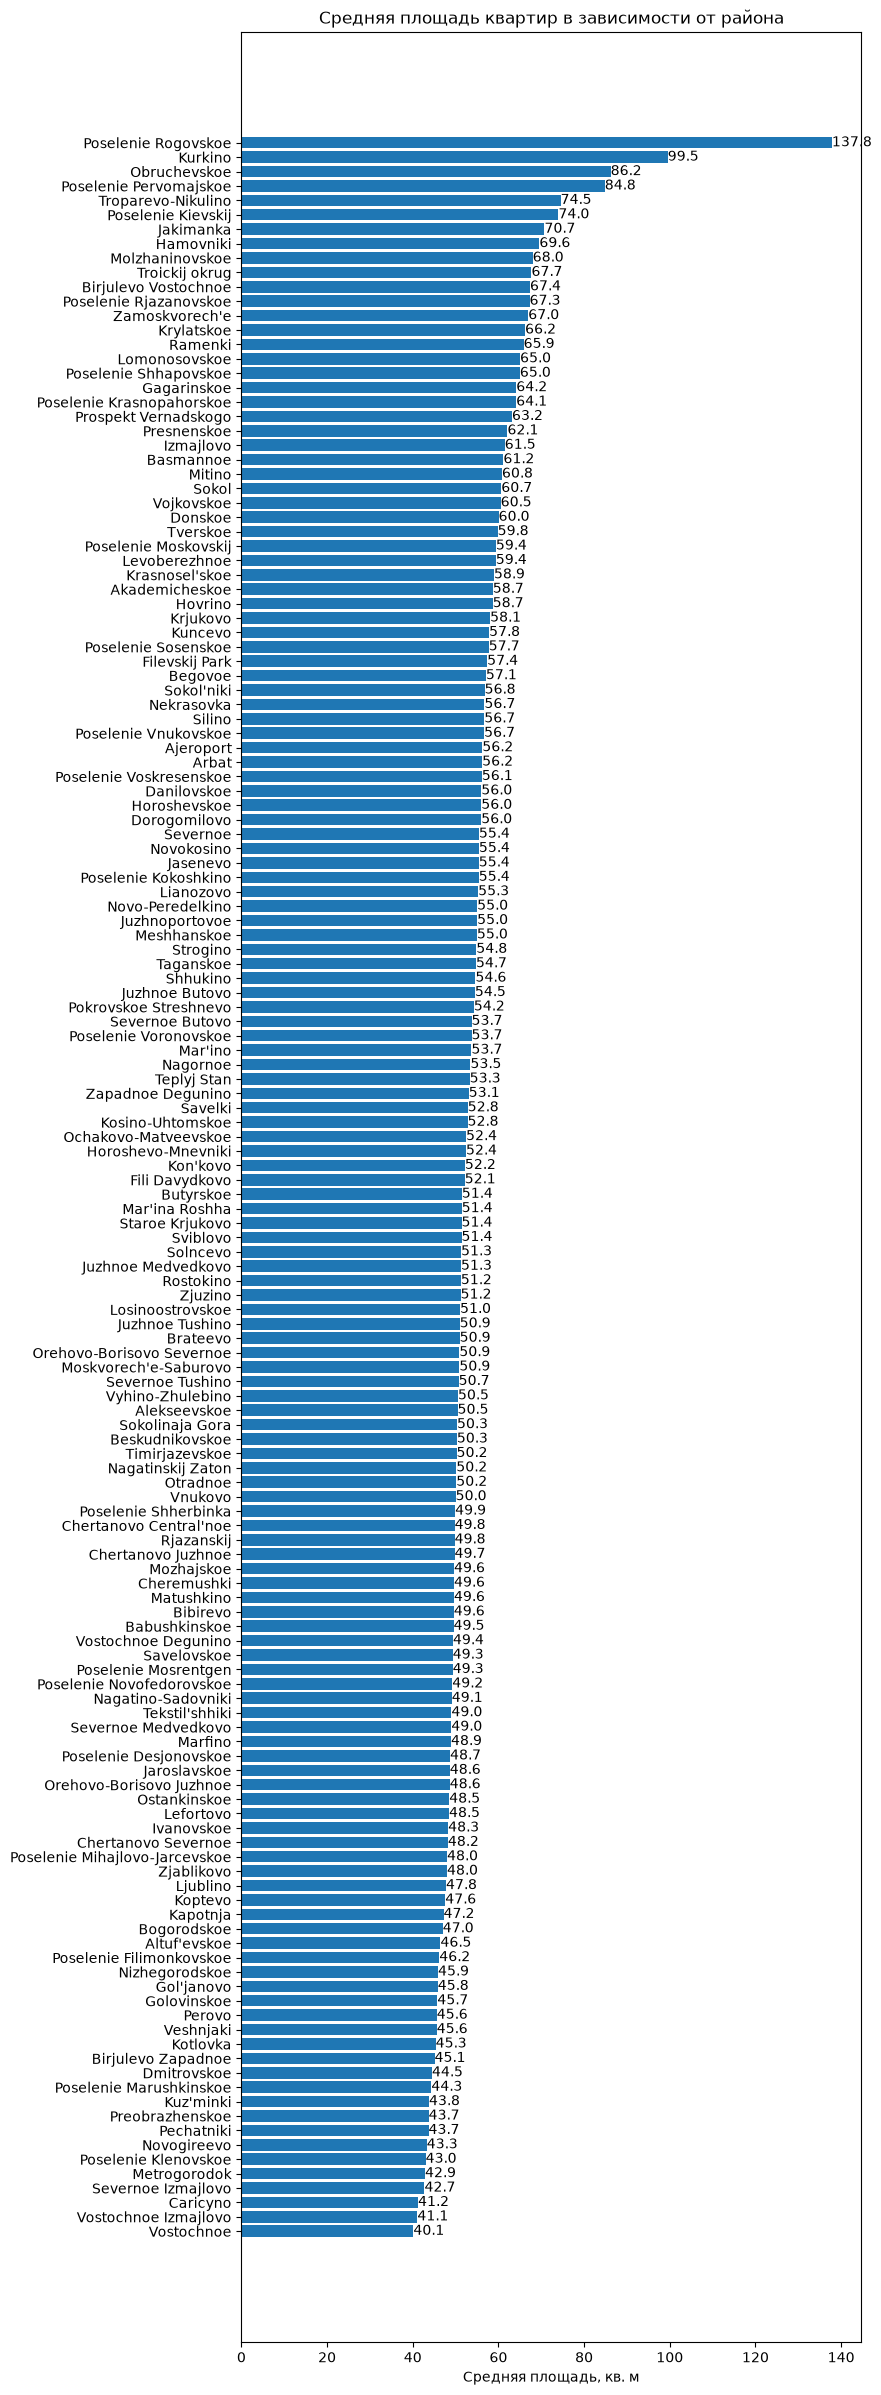

In [29]:
means = df.groupby("sub_area")["full_sq"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 30))
bars = ax.barh(means.index, means.values)
ax.bar_label(bars, fmt='%.1f')
ax.set(xlabel='Средняя площадь, кв. м', title='Средняя площадь квартир в зависимости от района')
plt.show()

7. Постройте график изменения медианной цены на квартиру менее 50 кв. метров за период с 2011 до 2014 года*

\* Задание на доп. балл

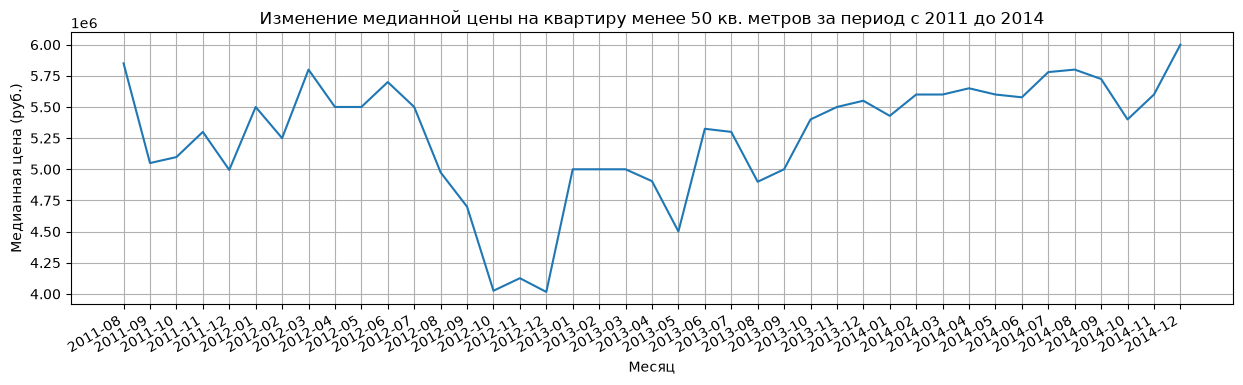

In [30]:
small = df[(df["full_sq"] < 50) & (df["timestamp"].dt.year >= 2011) & (df["timestamp"].dt.year <= 2014)]
month = small.groupby(small["timestamp"].dt.strftime("%Y-%m"))["price_doc"].median()

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(month.index, month.values)
ax.set(title='Изменение медианной цены на квартиру менее 50 кв. метров за период с 2011 до 2014', xlabel='Месяц', ylabel='Медианная цена (руб.)')
ax.grid()
fig.autofmt_xdate()
plt.show()